# Demo: Event Summarization using SmolVLM

This notebook provides a demonstration for the second task of the assignment. Given the strong performance of vision-language models across a variety of tasks, we use an efficient, lightweight model: [SmolVLM 2](https://huggingface.co/blog/smolvlm2)
The goal of this notebook is to guide you on how to: design prompts for event detection, process model outputs, and evaluate the quality of detected events.
You are expected to build upon this baseline and critically evaluate your chosen approaches.

In [1]:
!pip install num2words
!pip install av
!pip install --upgrade transformers
!pip install opencv-python

SmolVLM2 is a lightweight vision-language model designed for efficient video understanding with relatively few parameters. The material presented here is largely based on the original documentation and is intended to provide a starting point for developing your own approach.

In [2]:
from transformers import AutoProcessor
import os

cache_path = r"C:\Users\Boop\.cache\huggingface\hub\models--HuggingFaceTB--SmolVLM2-2.2B-Instruct\snapshots\482adb537c021c86670beed01cd58990d01e72e4"

processor = AutoProcessor.from_pretrained(cache_path)
print("✅ Processor loaded!")

c:\Users\Boop\anaconda3\envs\python3-9\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Processor loaded!


In [3]:
from transformers import AutoProcessor, AutoModelForImageTextToText
import torch
import cv2
from PIL import Image
import random
model_path = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"
processor = AutoProcessor.from_pretrained(model_path)
model = AutoModelForImageTextToText.from_pretrained(
    model_path,
    torch_dtype=torch.bfloat16,
).to("cuda")

`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 2/2 [00:08<00:00,  4.41s/it]


Since SmolVLM2 is a vision-language model (VLM), you will need to design an appropriate prompt for the task. The prompt can be flexible and should be adapted based on the type of output you want (e.g., event lists, descriptions, or timestamps).

Vision-language models process visual inputs (such as frames or videos) together with text by encoding them into a shared representation space. The exact input format may vary across models.

In our case, the HuggingFace implementation handles most of the input preprocessing (e.g., frame sampling and formatting), allowing you to focus primarily on prompt design and output parsing.

In [4]:
#load relative path to video_25.mp4
relative_path = os.path.join("..", "Moment-Retrieval-and-Video-Summarization", "TVSum", "video_25.mp4")
video_path = os.path.abspath(relative_path)
print(video_path)
print("File exists:", os.path.exists(video_path))

c:\Users\Boop\Workspace\ComputerVision\Moment-Retrieval-and-Video-Summarization\TVSum\video_25.mp4
File exists: True


In [28]:
import json
import re
from datetime import datetime, timezone
from pathlib import Path

def save_generated_annotation(generated_text, file_path="generated_annotations_trials.txt"):

    file_path = Path(file_path)

    text = generated_text[0] if isinstance(generated_text, list) else str(generated_text)

    # Split assistant response
    assistant_marker = "Assistant:"
    assistant_idx = text.rfind(assistant_marker)

    if assistant_idx != -1:
        prompt_part = text[:assistant_idx].strip()
        assistant_response = text[assistant_idx + len(assistant_marker):].strip()
    else:
        prompt_part = text.strip()
        assistant_response = ""

    # Try to extract only the prompt after the last "Frame from xx:xx\n\n"
    frame_matches = list(re.finditer(r":\n\n", prompt_part))
    if frame_matches:
        last_match = frame_matches[-1]
        prompt = prompt_part[last_match.end():].strip()
    else:
        prompt = prompt_part

    # Count frames analysed
    frames_analysed = len(re.findall(r"\nFrame from ", text))

    record = {
        "timestamp_saved": datetime.now(timezone.utc).isoformat(),
        "frames_analysed": frames_analysed,
        "prompt": prompt,
        "assistant_response": assistant_response        
    }

    with file_path.open("a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n\n")

    return record


def load_generated_annotations(file_path="generated_annotations_trials.txt"):
    """
    Load all saved annotation records from the JSONL file.
    """
    file_path = Path(file_path)
    if not file_path.exists():
        return []

    records = []
    with file_path.open("r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                records.append(json.loads(line))
    return records

In [30]:
import torch

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        name = torch.cuda.get_device_name(i)
        vram = torch.cuda.get_device_properties(i).total_memory / 1024**3
        print(f"GPU {i}: {name} — {vram:.1f} GB VRAM")
else:
    print("No GPU found — running on CPU")

GPU 0: NVIDIA GeForce RTX 4060 Laptop GPU — 8.0 GB VRAM


In [34]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "video", "path": video_path},
            {"type": "text", "text": """Describe what is happening in the video, sequentially focusing on the most important events. 
             Describe the events in detail, including the people involved, their appearance, their actions, and any relevant context. 
             Avoid generic descriptions and focus on specific moments that stand out. 
             List the events in order of occurrence."""}
        ]
    },
    
]

inputs = processor.apply_chat_template(
    messages,
    num_frames=100,  # more frames = better coverage
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device, dtype=torch.bfloat16)

generated_ids = model.generate(
    **inputs,
    do_sample=False,
    max_new_tokens=512,
    repetition_penalty=1.3,      # penalises repeating the same phrases
    no_repeat_ngram_size=4,      # forbids repeating any 4-word sequence
)

generated_texts = processor.batch_decode(generated_ids, skip_special_tokens=True)
print(generated_texts[0])
save_generated_annotation(generated_texts[0])

c:\Users\Boop\anaconda3\envs\python3-9\lib\site-packages\transformers\video_processing_utils.py:879: UserWarning: `torchcodec` is not installed and cannot be used to decode the video by default. Falling back to `torchvision`. Note that `torchvision` decoding is deprecated and will be removed in future versions. 
  warnings.warn(
c:\Users\Boop\anaconda3\envs\python3-9\lib\site-packages\transformers\video_utils.py:524: UserWarning: Using `torchvision` for video decoding is deprecated and will be removed in future versions. Please use `torchcodec` instead.
  warnings.warn(
c:\Users\Boop\anaconda3\envs\python3-9\lib\site-packages\torchvision\io\_video_deprecation_warning.py:5: UserWarning: The video decoding and encoding capabilities of torchvision are deprecated from version 0.22 and will be removed in version 0.24. We recommend that you migrate to TorchCodec, where we'll consolidate the future decoding/encoding capabilities of PyTorch: https://github.com/pytorch/torchcodec
  warnings.war

User: You are provided the following series of one hundred frames from a 0:04:34 [H:MM:SS] video.

Frame from 00:01:
Frame from 00:03:
Frame from 00:06:
Frame from 00:09:
Frame from 00:11:
Frame from 00:14:
Frame from 00:17:
Frame from 00:20:
Frame from 00:22:
Frame from 00:25:
Frame from 00:28:
Frame from 00:31:
Frame from 00:33:
Frame from 00:36:
Frame from 00:39:
Frame from 00:42:
Frame from 00:44:
Frame from 00:47:
Frame from 00:50:
Frame from 00:53:
Frame from 00:55:
Frame from 00:58:
Frame from 01:01:
Frame from 01:04:
Frame from 01:06:
Frame from 01:09:
Frame from 01:12:
Frame from 01:15:
Frame from 01:17:
Frame from 01:20:
Frame from 01:23:
Frame from 01:26:
Frame from 01:28:
Frame from 01:31:
Frame from 01:34:
Frame from 01:37:
Frame from 01:39:
Frame from 01:42:
Frame from 01:45:
Frame from 01:48:
Frame from 01:50:
Frame from 01:53:
Frame from 01:56:
Frame from 01:59:
Frame from 02:01:
Frame from 02:04:
Frame from 02:07:
Frame from 02:10:
Frame from 02:12:
Frame from 02:15:
F

{'timestamp_saved': '2026-05-10T18:34:07.668665+00:00',
 'frames_analysed': 100,
 'prompt': 'Describe what is happening in the video, sequentially focusing on the most important events. \n             Describe the events in detail, including the people involved, their appearance, their actions, and any relevant context. \n             Avoid generic descriptions and focus on specific moments that stand out. \n             List the events in order of occurrence.',
 'assistant_response': "The video starts with an aerial view of a cityscape featuring tall buildings under overcast skies. A person wearing headphones takes photos while standing near graffiti-covered walls. They then walk through crowded streets before entering a building where they take more pictures inside. Next to them sits another individual holding up his camera for someone else's photo. Inside, two individuals sit at tables covered by red Coca Cola cans; later, we see this same table set outside against a backdrop of blu

In [33]:
save_generated_annotation(generated_texts[0])

{'timestamp_saved': '2026-05-10T18:22:39.936835+00:00',
 'frames_analysed': 50,
 'prompt': 'You are an expert video annotator. Watch this video carefully and identify between 4 and 10 salient events.\n\nA salient event is something important for understanding the overall message or narrative of the video.\n\nFor each event provide:\n- A concise 1-2 sentence description of what happens\n- The approximate timestamp where it occurs (MM:SS format)\n- Only include events that are clearly visible and meaningful\n\nFormat your response EXACTLY like this:\nSalient event 1: [description], [MM:SS]\nSalient event 2: [description], [MM:SS]\n...and so on.\n\nFocus on actions, transitions, and key moments. Be specific about what people do, not just what the scene looks like.',
 'assistant_response': 'Salient event 3: Person in blue shirt taking picture with camera while wearing earphones.\nSalent event 4: Group of young men playing soccer near wall graffiti.\nSalient Event 5: Man sitting at table ea

The detected events are often highly descriptive, but they do not always capture the most important or salient moments in the video.

To address this, you may explore alternative strategies. One approach is to use a language model (LLM) to process frame-level descriptions generated from the video.

For example, you can experiment with randomly sampling frames from the video, generating descriptions for each frame using a vision-language model (VLM), and then aggregating these descriptions into a structured set of events using an LLM.


In [8]:
def sample_frames(video_path, num_frames):
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames == 0:
        raise ValueError("Video has no frames.")

    frame_indices = sorted(random.sample(range(total_frames), min(num_frames, total_frames)))

    frames = []
    current_idx = 0
    target_idx_set = set(frame_indices)

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        if current_idx in target_idx_set:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(Image.fromarray(frame))

        current_idx += 1

    cap.release()
    return frames

In [9]:
frames = sample_frames(video_path, 4)
print(f"✅ Got {len(frames)} frames")

✅ Got 4 frames


In [10]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "url": frames[0]},
            {"type": "image", "url": frames[1]},
            {"type": "image", "url": frames[2]},
            {"type": "image", "url": frames[3]},
            {"type": "text", "text": "Describe the most relevant events in the video, list each event sequentially, using a numbered format. Describe it in terms of the actions different persons take"}
        ]
    },
]
inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device, dtype=torch.bfloat16)

You may improve event detection by splitting the video into smaller temporal segments and prompting the VLM on each segment separately. The resulting partial event descriptions can then be combined into a single, coherent list using an LLM.

Crucially, you must define an evaluation scheme for event coverage, for example:
-How many annotated events are correctly detected?
-Which events are missed or incorrectly predicted?
-How does performance change with different prompting or segmentation strategies?

In [11]:
generated_ids = model.generate(**inputs, do_sample=False, max_new_tokens=256)

generated_texts = processor.batch_decode(
    generated_ids,
    skip_special_tokens=True,
)

print(generated_texts[0])

User:















Describe the most relevant events in the video, list each event sequentially, using a numbered format. Describe it in terms of the actions different persons take
Assistant: In the first image, a group of people are participating in a physical activity, possibly a game or exercise. They are wearing casual clothing and are engaged in a physical activity, with one person in the foreground wearing a maroon shirt and another in the background wearing a red shirt.

In the second image, a group of people are participating in a physical activity, possibly a game or exercise. They are wearing casual clothing and are engaged in a physical activity, with one person in the foreground wearing a maroon shirt and another in the background wearing a red shirt.

In the third image, a group of people are walking on a street. The buildings in the background are painted in various colors, and there are people walking on the street. The image is taken from an aerial perspective, lookin

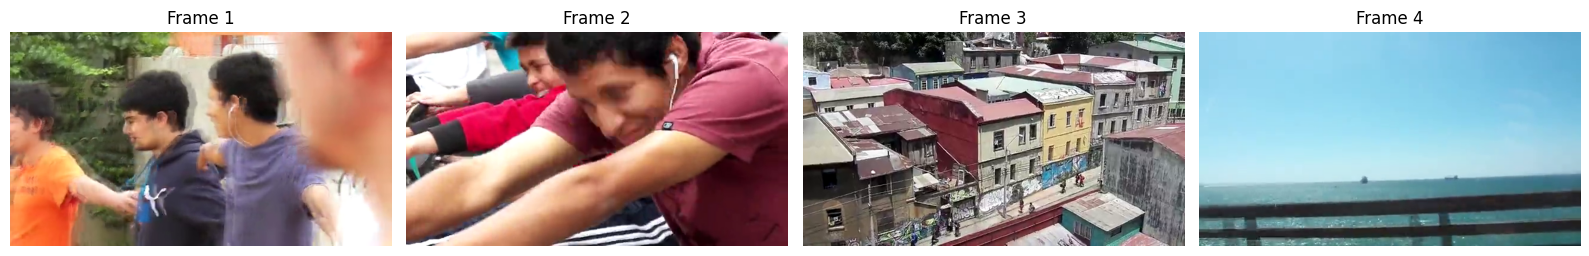

In [12]:
import matplotlib.pyplot as plt

n = len(frames)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))

if n == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    ax.imshow(frames[i])
    ax.set_title(f"Frame {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

The generated outputs may be quite descriptive. While this can introduce noise, it also provides an opportunity to infer potential events through reasoning over these descriptions.

Therefore, one possible strategy is to first generate scene-level descriptions using a vision-language model (VLM), and then further process these descriptions using a language model (LLM) to extract structured events.

The choice of strategy is left to you. You are expected to design and implement an approach that produces meaningful event representations from the video.